In [2]:
import torch
import librosa
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from muq import MuQ


In [2]:
from embedding_extraction import extract_embedding
data_dir = 'Data/nsynth-valid.jsonwav/nsynth-valid/audio'
embeddings = []
filenames = []
file_instruments = []

def extract_instrument(filename):
    return filename.split("_")[0]  


wav_entries = []

for audio_file in tqdm(os.listdir(data_dir)):
    if audio_file.endswith('.wav'):
        file_path = os.path.join(data_dir, audio_file)
        embedding = extract_embedding(file_path)
        embeddings.append(embedding)
        filenames.append(audio_file)
        instrument = extract_instrument(audio_file)
        file_instruments.append(instrument)

embeddings = np.array(embeddings)
df = pd.DataFrame(embeddings)
df['instrument'] = file_instruments
df['filename'] = filenames

df.to_csv("muq_embedding_nsynth.csv", index=False)
torch.save({'embeddings': torch.tensor(embeddings), 'instruments': file_instruments, 'filenames': filenames}, "muq_embeddings.pt")

print("✅ Extraction terminée !")
print("Dimensions embeddings :", embeddings.shape)  # (N, D)

/home/aguerouani/free-gen-playlist/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/aguerouani/free-gen-playlist/.venv/lib/python3.12/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


NameError: name 'tqdm' is not defined

Loaded embeddings shape: (12678, 1024)
t-SNE result shape: (12678, 2)
✅ t-SNE plot saved as tsne_muQ_embeddings_nsynth.png


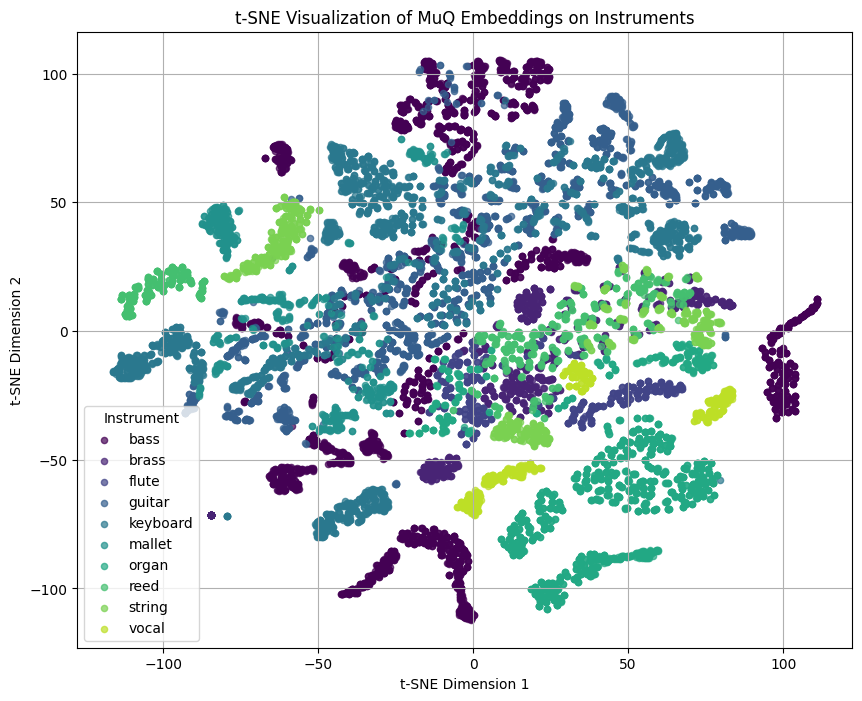

In [5]:
from tsne_vis import load_embeddings
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np


csv_path = "muq_embedding_nsynth.csv"
data = pd.read_csv(csv_path)
instruments = data['instrument']  #  the second last column is 'instrument'
filenames = data['filename']  #  the last column is 'filename'
data.drop(columns=['instrument', 'filename'], inplace=True)
embeddings , instruments , filenames = data.to_numpy(), instruments.to_numpy(), filenames.to_numpy()
X_2d = TSNE(n_components=2, random_state=42).fit_transform(embeddings)
print("Loaded embeddings shape:", embeddings.shape)
print("t-SNE result shape:", X_2d.shape)
plt.figure(figsize=(10, 8))
# Obtenir la liste unique des instruments
unique_instruments = np.unique(instruments)
n_classes = len(unique_instruments)

cmap = plt.get_cmap("viridis")
colors = [cmap(i / n_classes) for i in range(n_classes)]
class_to_color = {cls: colors[i] for i, cls in enumerate(unique_instruments)}
# Plot instrument par instrument
for instrument in unique_instruments:
    idx = instruments == instrument
    plt.scatter(X_2d[idx, 0], X_2d[idx, 1], label=instrument, color=class_to_color[instrument], alpha=0.7, s=20)
plt.title("t-SNE Visualization of MuQ Embeddings on Instruments")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Instrument")
plt.grid(True)
# Sauvegarde du graphique
plt.savefig("tsne_muQ_embeddings_nsynth.png", dpi=300)
print("✅ t-SNE plot saved as tsne_muQ_embeddings_nsynth.png")